# Notebook 03 - Modelling, Tuning, Selection and Saving

**Goal:** train five classification models, tune them, compare them fairly, pick the best one with a rule fixed *before* looking at
the test set, explain it, and save everything the Streamlit app needs.

**Pipeline of this notebook**

1. Load the same train/test split used everywhere (`src.data_utils.get_split`).
2. **Baseline:** train each model with default settings (5-fold cross-validation + one test evaluation).
3. **Tuning:** `GridSearchCV` or `RandomizedSearchCV` for every model, scored with ROC-AUC.
4. **Before vs after tuning** comparison.
5. **Feature importance** (permutation importance).
6. **Selection:** best model = highest tuned *cross-validated* ROC-AUC on the training data.
7. **Error analysis:** where does the model fail? Are its probabilities trustworthy?
8. **Save** every tuned pipeline with Joblib, plus `metrics.json`, `reference.json`, `error_analysis.json` and the figures.
9. **Verify** the saved files by reloading them.

**Why ROC-AUC is the main metric:** only about 20% of customers churn, so accuracy is misleading. ROC-AUC ranks customers across
*all* thresholds, so it is a fair way to compare models on imbalanced data. Precision, recall, F1 and the confusion matrix are
reported too, because the PDF requires them.

> This notebook takes roughly 10-15 minutes to run on a laptop (the tuning is the slow part).

In [ ]:
import os, sys, warnings
from pathlib import Path

# Work from the project root whether the notebook is opened from the root or from notebooks/
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
print("Project root:", ROOT)

In [2]:
import json, time, platform
from datetime import datetime, timezone

import joblib
import numpy as np
import pandas as pd
import sklearn
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, cross_val_score

from src.data_utils import (RANDOM_STATE, RAW_FEATURES, TARGET, clean, get_split, iqr_outlier_counts,
                            load_raw, validate)
from src.pipeline import MODEL_NAMES, build_pipeline
from src.evaluation import (evaluate_pipeline, slug, reference_profile, error_analysis)
from src import plots

T_START = time.time()
MODELS_DIR = ROOT / "models"
ALL_MODELS_DIR = MODELS_DIR / "all_models"
FIG_DIR = ROOT / "reports" / "figures"
for d in (MODELS_DIR, ALL_MODELS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 1. Load the data and the split

Same cleaning and the same stratified 80/20 split as notebook 02 (fixed `random_state`), so every number here is reproducible.
`CV` is the 5-fold stratified cross-validation scheme used for *every* model, so they are compared on the same folds.

In [3]:
raw = load_raw()
quality = validate(raw)
outliers = iqr_outlier_counts(raw).to_dict(orient="records")
df = clean(raw)
X_train, X_test, y_train, y_test = get_split(df)

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print(f"Rows: raw={len(raw)}  clean={len(df)}  train={len(X_train)}  test={len(X_test)}")
print(f"Churn rate: train={y_train.mean():.3f}  test={y_test.mean():.3f}")
print(f"Accuracy of always predicting 'stays' on the test set: {1 - y_test.mean():.3f}")
print("Models to compare:", MODEL_NAMES)

Rows: raw=10000  clean=10000  train=8000  test=2000
Churn rate: train=0.204  test=0.203
Accuracy of always predicting 'stays' on the test set: 0.796
Models to compare: ['Logistic Regression', 'KNN', 'SVM', 'Random Forest', 'Gradient Boosting']


## 2. Baseline models (default settings)

Each model goes through the **same pipeline** (feature engineering, imputation, scaling, encoding, model). For every model we record:

* the 5-fold cross-validated ROC-AUC on the training data (used later for selection),
* the test-set metrics at the default 0.5 threshold,
* the test-set metrics at a threshold chosen from out-of-fold *training* predictions (maximises F1).

| Model | Why it is here |
|---|---|
| Logistic Regression | simple, fast, interpretable baseline |
| KNN | distance-based; very sensitive to feature scaling |
| SVM (RBF kernel) | flexible non-linear boundary |
| Random Forest | many decision trees averaged; robust |
| Gradient Boosting | trees built one after another, each fixing the previous errors |

In [4]:
baseline = {}
for name in MODEL_NAMES:
    t0 = time.time()
    pipe = build_pipeline(name)
    scores = cross_val_score(pipe, X_train, y_train, cv=CV, scoring="roc_auc")
    pipe.fit(X_train, y_train)
    res = evaluate_pipeline(pipe, X_train, y_train, X_test, y_test, CV)
    res["cv_roc_auc_mean"] = float(scores.mean())
    res["cv_roc_auc_std"] = float(scores.std())
    baseline[name] = res
    print(f"{name:20s} CV AUC = {scores.mean():.4f} +/- {scores.std():.4f} | "
          f"test AUC = {res['test_default_threshold']['roc_auc']:.4f} ({time.time()-t0:.0f}s)")

Logistic Regression  CV AUC = 0.8415 +/- 0.0112 | test AUC = 0.8492 (1s)


KNN                  CV AUC = 0.7851 +/- 0.0174 | test AUC = 0.7880 (1s)


SVM                  CV AUC = 0.8255 +/- 0.0174 | test AUC = 0.8358 (37s)


Random Forest        CV AUC = 0.8504 +/- 0.0142 | test AUC = 0.8531 (17s)


Gradient Boosting    CV AUC = 0.8635 +/- 0.0099 | test AUC = 0.8701 (12s)


## 3. Hyperparameter tuning

Hyperparameters are settings chosen *before* training (for example how deep a tree may grow). We search for good values with
cross-validation **on the training data only**; the test set plays no part.

* `GridSearchCV` tries every combination - used for the two small search spaces (Logistic Regression, KNN).
* `RandomizedSearchCV` tries a fixed number of random combinations - used for the larger spaces (SVM, Random Forest, Gradient Boosting).
* Scoring is `roc_auc`.

Two practical notes:

* The SVM is searched with `probability=False` because probability estimation is about five times slower; the final SVM is rebuilt with
  the best settings and `probability=True`, so the app can show probabilities.
* The KNN grid goes up to 81 neighbours because an earlier, narrower grid picked its edge value - a sign the grid was too small.

In [5]:
SEARCH_SPACES = {
    "Logistic Regression": ("grid", {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100]}, None),
    "KNN": ("grid", {"model__n_neighbors": [5, 9, 15, 21, 31, 41, 61, 81],
                     "model__weights": ["uniform", "distance"],
                     "model__p": [1, 2]}, None),
    "SVM": ("random", {"model__C": [0.3, 1, 3, 10, 30],
                       "model__gamma": ["scale", 0.01, 0.03, 0.1]}, 8),
    "Random Forest": ("random", {"model__n_estimators": [150, 250, 400],
                                 "model__max_depth": [None, 6, 8, 10, 12, 16],
                                 "model__min_samples_leaf": [1, 2, 4, 8],
                                 "model__max_features": ["sqrt", 0.5, 0.8]}, 20),
    "Gradient Boosting": ("random", {"model__n_estimators": [100, 200, 300],
                                     "model__learning_rate": [0.03, 0.05, 0.1],
                                     "model__max_depth": [2, 3, 4, 5],
                                     "model__subsample": [0.7, 0.85, 1.0],
                                     "model__min_samples_leaf": [1, 10, 30]}, 20),
}

In [6]:
tuned = {}          # evaluation results per model
tuned_models = {}   # fitted pipelines per model

for name in MODEL_NAMES:
    t0 = time.time()
    kind, space, n_iter = SEARCH_SPACES[name]

    search_params = {"probability": False} if name == "SVM" else {}
    search_pipe = build_pipeline(name, **search_params)
    if kind == "grid":
        search = GridSearchCV(search_pipe, space, scoring="roc_auc", cv=CV, n_jobs=1)
    else:
        search = RandomizedSearchCV(search_pipe, space, n_iter=n_iter, scoring="roc_auc",
                                    cv=CV, n_jobs=1, random_state=RANDOM_STATE)
    search.fit(X_train, y_train)

    best_params = {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v)
                   for k, v in search.best_params_.items()}

    # Rebuild the final model with the best settings (probability=True for the SVM) and fit on ALL training rows
    final = build_pipeline(name, **best_params).fit(X_train, y_train)
    res = evaluate_pipeline(final, X_train, y_train, X_test, y_test, CV)
    res.update({
        "search_type": "GridSearchCV" if kind == "grid" else "RandomizedSearchCV",
        "n_candidates": int(len(search.cv_results_["params"])),
        "best_params": best_params,
        "cv_roc_auc_mean": float(search.best_score_),
        "cv_roc_auc_std": float(search.cv_results_["std_test_score"][search.best_index_]),
    })
    tuned[name] = res
    tuned_models[name] = final
    print(f"{name:20s} {res['search_type']:20s} best CV AUC = {search.best_score_:.4f} | "
          f"test AUC = {res['test_default_threshold']['roc_auc']:.4f} ({time.time()-t0:.0f}s)")
    print("   best parameters:", best_params)

Logistic Regression  GridSearchCV         best CV AUC = 0.8417 | test AUC = 0.8491 (4s)
   best parameters: {'C': 30}


KNN                  GridSearchCV         best CV AUC = 0.8422 | test AUC = 0.8437 (25s)
   best parameters: {'n_neighbors': 61, 'p': 2, 'weights': 'distance'}


SVM                  RandomizedSearchCV   best CV AUC = 0.8327 | test AUC = 0.8463 (54s)
   best parameters: {'gamma': 0.01, 'C': 1}


Random Forest        RandomizedSearchCV   best CV AUC = 0.8613 | test AUC = 0.8610 (242s)
   best parameters: {'n_estimators': 150, 'min_samples_leaf': 8, 'max_features': 0.5, 'max_depth': 16}


Gradient Boosting    RandomizedSearchCV   best CV AUC = 0.8637 | test AUC = 0.8707 (199s)
   best parameters: {'subsample': 0.7, 'n_estimators': 100, 'min_samples_leaf': 30, 'max_depth': 4, 'learning_rate': 0.05}


## 4. Before vs after tuning

The PDF requires comparing performance before and after tuning. **Tuning is not guaranteed to help** - where the "after" numbers are not
better, that is a real result and it is kept as it is. (The "CV AUC after" value is the best score seen during the search, so it is
slightly optimistic by construction; the *test* columns are the unbiased comparison.)

In [7]:
rows = []
for name in MODEL_NAMES:
    b, t = baseline[name], tuned[name]
    rows.append({
        "Model": name, "Search": t["search_type"],
        "CV AUC before": b["cv_roc_auc_mean"], "CV AUC after": t["cv_roc_auc_mean"],
        "Test AUC before": b["test_default_threshold"]["roc_auc"], "Test AUC after": t["test_default_threshold"]["roc_auc"],
        "Test F1 before": b["test_default_threshold"]["f1"], "Test F1 after": t["test_default_threshold"]["f1"],
    })
before_after = pd.DataFrame(rows).set_index("Model")
display(before_after.round(4))
print("Change in test ROC-AUC (after - before):")
print((before_after["Test AUC after"] - before_after["Test AUC before"]).round(4).to_string())

,Search,CV AUC before,CV AUC after,Test AUC before,Test AUC after,Test F1 before,Test F1 after
Model,,,,,,,
Logistic Regression,GridSearchCV,0.8415,0.8417,0.8492,0.8491,0.5587,0.5606
KNN,GridSearchCV,0.7851,0.8422,0.7880,0.8437,0.5154,0.4720
SVM,RandomizedSearchCV,0.8255,0.8327,0.8358,0.8463,0.5660,0.4521
Random Forest,RandomizedSearchCV,0.8504,0.8613,0.8531,0.8610,0.5781,0.5728
Gradient Boosting,RandomizedSearchCV,0.8635,0.8637,0.8701,0.8707,0.5936,0.5901


Change in test ROC-AUC (after - before):
Model
Logistic Regression   -0.0001
KNN                    0.0558
SVM                    0.0105
Random Forest          0.0080
Gradient Boosting      0.0006


**Why F1 at the 0.5 threshold can go down after tuning:** we tuned for ROC-AUC, which ranks customers across all thresholds. F1 at 0.5
depends on one fixed cut-off, so it can move in either direction. The decision threshold is handled separately (section 8).

## 5. Feature importance (permutation importance)

Shuffle one input column at a time on the test set and measure how much ROC-AUC drops. A bigger drop means the model relied more on that
column. It works for every model type and uses the raw input columns, which are easy to explain.
It shows what the *model uses*, not what *causes* churn.

In [8]:
for name in MODEL_NAMES:
    perm = permutation_importance(tuned_models[name], X_test, y_test, scoring="roc_auc",
                                  n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
    tuned[name]["permutation_importance"] = {
        col: {"mean": float(perm.importances_mean[i]), "std": float(perm.importances_std[i])}
        for i, col in enumerate(RAW_FEATURES)
    }
    print("done:", name)

# One table: importance of each input for each model
importance = pd.DataFrame({n: {k: v["mean"] for k, v in tuned[n]["permutation_importance"].items()} for n in MODEL_NAMES})
display(importance.sort_values(importance.columns[-1], ascending=False).round(4))

done: Logistic Regression


done: KNN


done: SVM


done: Random Forest


done: Gradient Boosting


,Logistic Regression,KNN,SVM,Random Forest,Gradient Boosting
age,0.1160,0.1285,0.1172,0.1191,0.1249
products_number,0.0993,0.1170,0.0966,0.1233,0.1108
active_member,0.0299,0.0115,0.0387,0.0265,0.0297
balance,0.0012,0.0276,0.0221,0.0440,0.0296
country,0.0162,0.0156,0.0174,0.0286,0.0185
gender,0.0104,0.0075,0.0057,0.0057,0.0065
estimated_salary,-0.0010,0.0007,-0.0023,0.0003,0.0013
credit_score,-0.0002,-0.0016,0.0003,0.0005,0.0006
tenure,0.0007,-0.0034,0.0011,-0.0018,0.0001
credit_card,-0.0004,0.0004,-0.0006,-0.0004,-0.0001


## 6. Choose the best model

**Selection rule (fixed before looking at the test set):** the model with the highest tuned *cross-validated* ROC-AUC on the training data.
The test set is only used afterwards to report honest numbers. If another model happens to score slightly higher on the test set, that
does not change the choice - switching after seeing test scores would be selecting a model *with* the test set.

In [9]:
ranking = sorted(MODEL_NAMES, key=lambda n: -tuned[n]["cv_roc_auc_mean"])
best_name = ranking[0]
reason = (f"{best_name} has the highest cross-validated ROC-AUC on the training data after tuning "
          f"({tuned[best_name]['cv_roc_auc_mean']:.4f}). ROC-AUC was chosen as the main metric because the classes are "
          "imbalanced (about 20% churn), so accuracy is misleading.")
print("Ranking by tuned CV ROC-AUC:")
for n in ranking:
    print(f"  {n:20s} {tuned[n]['cv_roc_auc_mean']:.4f} +/- {tuned[n]['cv_roc_auc_std']:.4f}")
print()
print("Best model:", best_name)
print(reason)

Ranking by tuned CV ROC-AUC:
  Gradient Boosting    0.8637 +/- 0.0083
  Random Forest        0.8613 +/- 0.0105
  KNN                  0.8422 +/- 0.0146
  Logistic Regression  0.8417 +/- 0.0109
  SVM                  0.8327 +/- 0.0129

Best model: Gradient Boosting
Gradient Boosting has the highest cross-validated ROC-AUC on the training data after tuning (0.8637). ROC-AUC was chosen as the main metric because the classes are imbalanced (about 20% churn), so accuracy is misleading.


In [10]:
# Final comparison table on the TEST set (threshold 0.5) - the metrics required by the PDF
rows = []
for n in ranking:
    m = tuned[n]["test_default_threshold"]
    rows.append({"Model": n, "Accuracy": m["accuracy"], "Precision": m["precision"], "Recall": m["recall"],
                 "F1": m["f1"], "ROC-AUC": m["roc_auc"]})
display(pd.DataFrame(rows).set_index("Model").round(3))

b = tuned[best_name]
print(f"\n{best_name}: confusion matrix at threshold 0.5 [[TN, FP], [FN, TP]] =",
      b["test_default_threshold"]["confusion_matrix"])
print(f"{best_name}: F1-optimised threshold = {b['tuned_threshold']:.2f} -> confusion matrix =",
      b["test_tuned_threshold"]["confusion_matrix"])

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Gradient Boosting,0.868,0.802,0.467,0.590,0.871
Random Forest,0.864,0.789,0.450,0.573,0.861
KNN,0.849,0.818,0.332,0.472,0.844
Logistic Regression,0.860,0.781,0.437,0.561,0.849
SVM,0.840,0.746,0.324,0.452,0.846



Gradient Boosting: confusion matrix at threshold 0.5 [[TN, FP], [FN, TP]] = [[1546, 47], [217, 190]]
Gradient Boosting: F1-optimised threshold = 0.29 -> confusion matrix = [[1419, 174], [135, 272]]


## 7. Error analysis of the selected model

A single score can hide where a model fails. On the test set we look at:

* **segments:** recall (churners caught), precision and how often customers in each group are flagged,
* **calibration:** when the model says "60% risk", do about 60% of those customers actually churn?

In [11]:
proba_best = tuned_models[best_name].predict_proba(X_test)[:, 1]
ea = error_analysis(X_test, y_test, proba_best, tuned[best_name]["tuned_threshold"])

for col, rows in ea["segments"].items():
    print(f"--- {col} ---")
    display(pd.DataFrame(rows).set_index("group").round(3))
print("Brier score (lower is better; 0.25 = uninformative at 50%):", round(ea["brier_score"], 4))

--- country ---


,n,n_churned,churn_rate,flag_rate,recall,precision
group,,,,,,
France,1021,175,0.171,0.168,0.589,0.599
Germany,504,151,0.300,0.381,0.788,0.620
Spain,475,81,0.171,0.173,0.617,0.610


--- gender ---


,n,n_churned,churn_rate,flag_rate,recall,precision
group,,,,,,
Female,930,233,0.251,0.282,0.704,0.626
Male,1070,174,0.163,0.172,0.621,0.587


--- active_member ---


,n,n_churned,churn_rate,flag_rate,recall,precision
group,,,,,,
0,968,266,0.275,0.299,0.718,0.661
1,1032,141,0.137,0.152,0.574,0.516


--- products_number ---


,n,n_churned,churn_rate,flag_rate,recall,precision
group,,,,,,
1,1013,270,0.267,0.330,0.707,0.572
2,918,77,0.084,0.047,0.273,0.488
3,59,50,0.847,1.000,1.000,0.847
4,10,10,1.000,1.000,1.000,1.000


--- age_group ---


,n,n_churned,churn_rate,flag_rate,recall,precision
group,,,,,,
31-40,868,99,0.114,0.073,0.323,0.508
41-50,492,172,0.350,0.494,0.808,0.572
51-60,152,89,0.586,0.678,0.888,0.767
60+,89,22,0.247,0.303,0.727,0.593
<=30,399,25,0.063,0.025,0.240,0.600


Brier score (lower is better; 0.25 = uninformative at 50%): 0.099


,n,mean_predicted,observed_rate
bin,,,
0-10%,952,0.055,0.039
10-20%,424,0.142,0.130
20-40%,303,0.282,0.277
40-60%,140,0.486,0.529
60-80%,86,0.705,0.779
80-100%,95,0.886,0.947


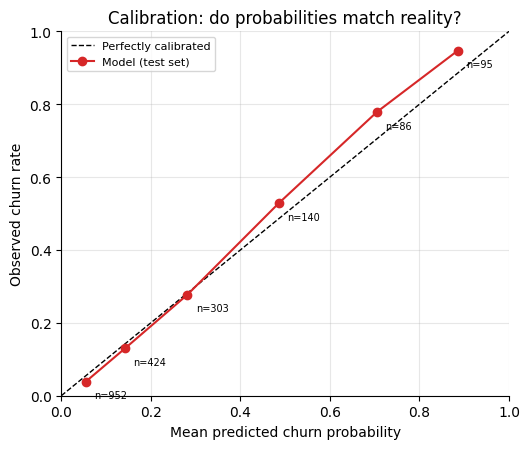

In [12]:
cal = pd.DataFrame(ea["calibration"]).set_index("bin")
display(cal.round(3))
plots.calibration_plot(ea)
plt.show()

**How to read the calibration table:** if `mean_predicted` and `observed_rate` are close in each row, the probabilities can be read as rough
frequencies. Where they differ, the probability is better used for *ranking* customers than as an exact percentage. Bins with few
customers (`n` is small) are noisy.

## 8. Save everything the app needs

* every tuned pipeline with **Joblib** (`models/all_models/*.joblib`) - the whole pipeline, so the app accepts raw customer inputs,
* the best model again as `models/final_model.joblib`,
* `metrics.json` (all numbers the app and report display - nothing is typed in by hand),
* `reference.json` (typical values and segment churn rates from the training split),
* `error_analysis.json`.

In [13]:
for name in MODEL_NAMES:
    joblib.dump(tuned_models[name], ALL_MODELS_DIR / f"{slug(name)}.joblib", compress=3)
joblib.dump(tuned_models[best_name], MODELS_DIR / "final_model.joblib", compress=3)

results = {n: {"baseline": baseline[n], "tuned": tuned[n]} for n in MODEL_NAMES}
metrics = {
    "meta": {
        "trained_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "quick_run": False,
        "python": platform.python_version(), "sklearn": sklearn.__version__,
        "pandas": pd.__version__, "numpy": np.__version__,
        "random_state": RANDOM_STATE,
        "n_rows_raw": int(len(raw)), "n_rows_clean": int(len(df)),
        "n_train": int(len(X_train)), "n_test": int(len(X_test)),
        "churn_rate_train": float(y_train.mean()), "churn_rate_test": float(y_test.mean()),
        "majority_class_accuracy_test": float(1 - y_test.mean()),
        "cv_folds": 5, "primary_metric": "roc_auc",
        "data_quality": quality, "outliers_iqr": outliers,
        "training_seconds": round(time.time() - T_START),
    },
    "model_order": ranking,
    "best_model": best_name,
    "selection_reason": reason,
    "models": results,
}
(MODELS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2))
(MODELS_DIR / "reference.json").write_text(json.dumps(reference_profile(X_train, y_train), indent=2))
(MODELS_DIR / "error_analysis.json").write_text(json.dumps({"model": best_name, **ea}, indent=2))

for p in sorted(MODELS_DIR.rglob("*")):
    if p.is_file():
        print(f"{str(p.relative_to(ROOT)):45s} {p.stat().st_size/1e6:7.2f} MB")

models/all_models/gradient_boosting.joblib       0.07 MB
models/all_models/knn.joblib                     0.30 MB
models/all_models/logistic_regression.joblib     0.00 MB
models/all_models/random_forest.joblib           2.16 MB
models/all_models/svm.joblib                     0.13 MB
models/error_analysis.json                       0.00 MB
models/feature_ablation.json                     0.00 MB
models/final_model.joblib                        0.07 MB
models/metrics.json                              0.07 MB
models/reference.json                            0.00 MB


## 9. Figures for the report and app

The same plotting functions are used by the Streamlit app, so charts in the app and the report always agree.

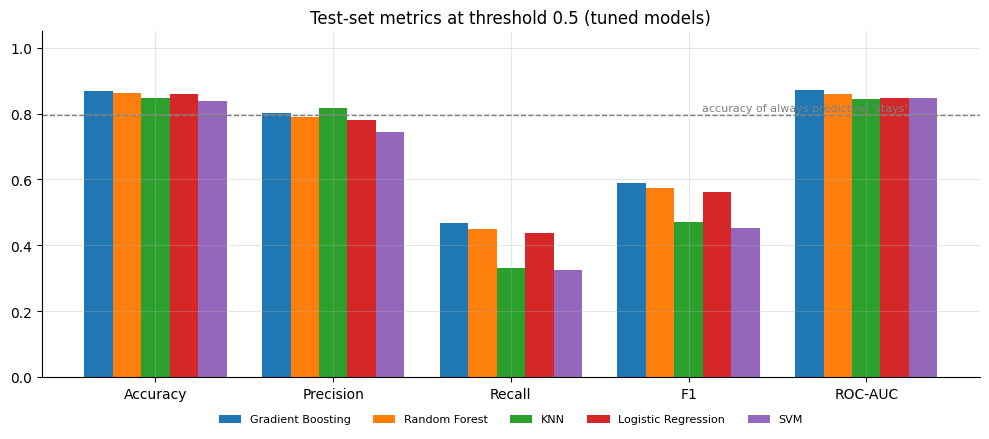

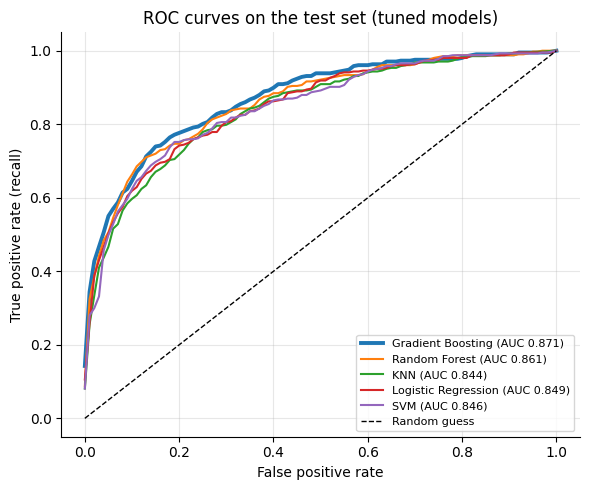

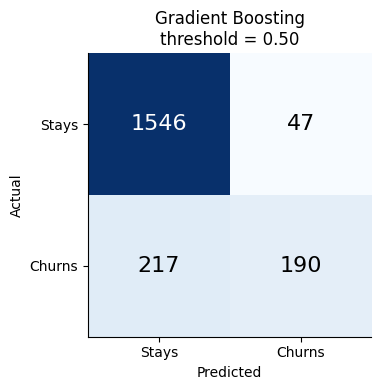

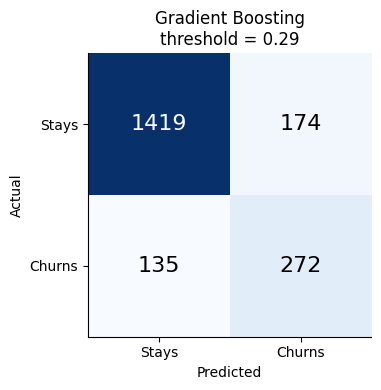

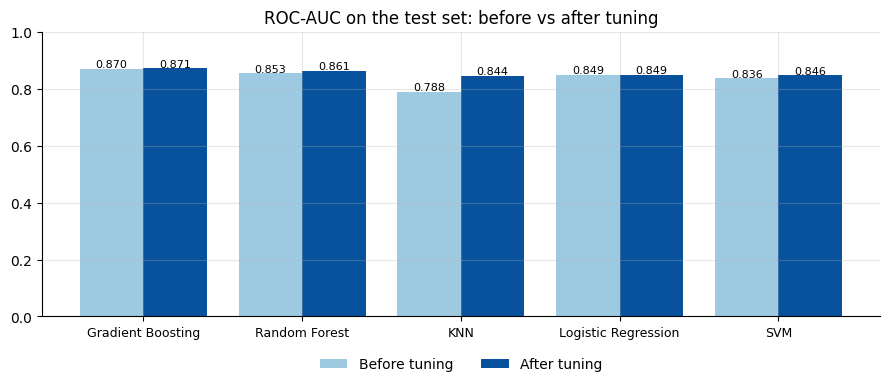

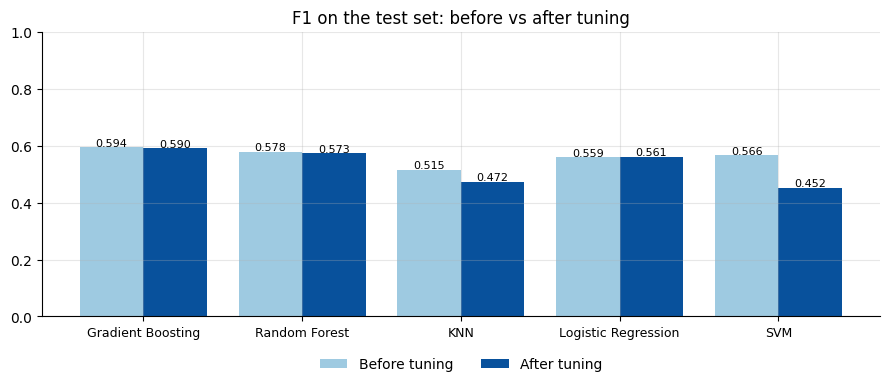

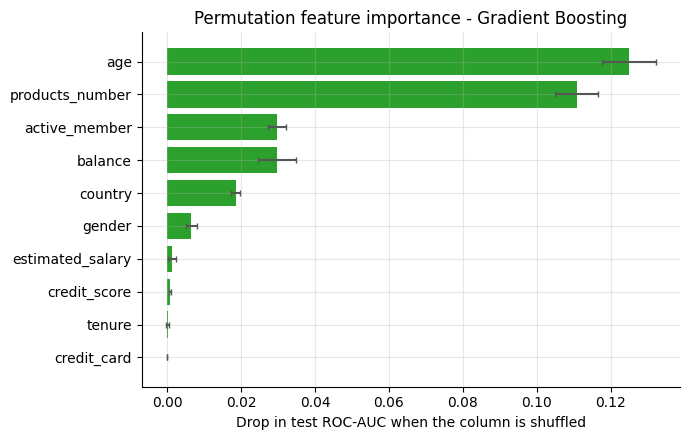

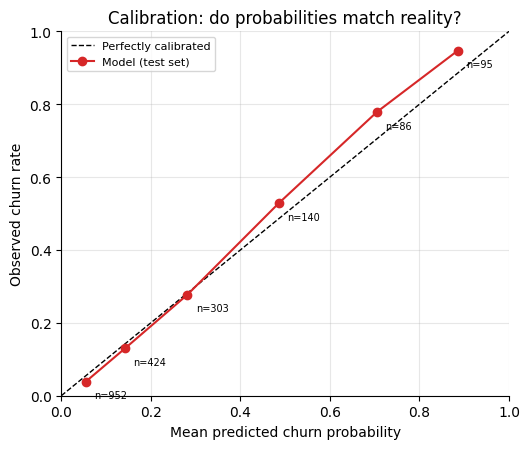

In [14]:
figs = {
    "06_model_comparison.png": plots.model_comparison(metrics),
    "07_roc_curves.png": plots.roc_curves(metrics, highlight=best_name),
    "08_confusion_matrix_best_default.png": plots.confusion_matrix_plot(metrics, best_name, "default"),
    "09_confusion_matrix_best_tuned_threshold.png": plots.confusion_matrix_plot(metrics, best_name, "tuned"),
    "10_tuning_before_after_auc.png": plots.tuning_before_after(metrics, "roc_auc"),
    "11_tuning_before_after_f1.png": plots.tuning_before_after(metrics, "f1"),
    "12_feature_importance_best.png": plots.feature_importance(metrics, best_name),
    "14_calibration.png": plots.calibration_plot(ea),
}
for fname, fig in figs.items():
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 10. Verify the saved files (never trust a save that was not reloaded)

Reload every saved model from disk and check that it predicts **exactly** what the in-memory model predicts on the whole test set.

In [15]:
ok = True
for name in MODEL_NAMES:
    reloaded = joblib.load(ALL_MODELS_DIR / f"{slug(name)}.joblib")
    same = np.allclose(reloaded.predict_proba(X_test), tuned_models[name].predict_proba(X_test))
    ok &= bool(same)
    print(f"{name:20s} reload matches in-memory model: {same}")

final = joblib.load(MODELS_DIR / "final_model.joblib")
same_final = np.allclose(final.predict_proba(X_test), tuned_models[best_name].predict_proba(X_test))
print(f"final_model.joblib matches {best_name}: {same_final}")
assert ok and same_final, "A saved model does not match the in-memory model!"

# One raw customer in, one probability out - exactly what the app does
customer = pd.DataFrame([{"credit_score": 650, "country": "Germany", "gender": "Female", "age": 45, "tenure": 3,
                          "balance": 120000.0, "products_number": 1, "credit_card": 1, "active_member": 0,
                          "estimated_salary": 80000.0}])[RAW_FEATURES]
print("\nExample customer churn probability:", round(float(final.predict_proba(customer)[0, 1]), 3))
print(f"Total time: {(time.time()-T_START)/60:.1f} minutes")

Logistic Regression  reload matches in-memory model: True
KNN                  reload matches in-memory model: True


SVM                  reload matches in-memory model: True
Random Forest        reload matches in-memory model: True


Gradient Boosting    reload matches in-memory model: True
final_model.joblib matches Gradient Boosting: True

Example customer churn probability: 0.739
Total time: 10.3 minutes


## 11. Summary

* Five models were trained, tuned with `GridSearchCV` / `RandomizedSearchCV`, and compared before and after tuning.
* The best model was chosen by cross-validated ROC-AUC on the training data only; the test set was used once for the final numbers.
* The error analysis shows where the model is strong or weak and whether its probabilities can be read as frequencies.
* All pipelines are saved with Joblib and verified by reloading. Next: the Streamlit app in `app/` reads these files.

Limitations and honest notes are in the report (`reports/Task04_Bank_Churn_Report.pdf`).